In [1]:
%pip install earthengine-api geemap pandas numpy matplotlib seaborn scikit-learn geopandas folium

  Using cached pyperclip-1.11.0-py3-none-any.whl.metadata (2.4 kB)
  Using cached pyasn1_modules-0.4.2-py3-none-any.whl.metadata (3.5 kB)
  Using cached pyasn1-0.6.4-py3-none-any.whl.metadata (8.4 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------- ----------------------- 1.0/2.5 MB 40.6 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 7.2 MB/s  0:00:00
   ---------------------------------------- 0.0/16.1 MB ? eta -:--:--
   --------- ------------------------------ 3.7/16.1 MB 18.1 MB/s eta 0:00:01
   --------------- ------------------------ 6.3/16.1 MB 15.4 MB/s eta 0:00:01
   ---------------------- ----------------- 8.9/16.1 MB 14.4 MB/s eta 0:00:01
   ----------------------------- ---------- 11.8/16.1 MB 13.9 MB/s eta 0:00:01
   ----------------------------------- ---- 14.4/16.1 MB 13.7 MB/s eta 0:00:01
   ---------------------------------------- 16.1/16.1 MB 13.2 MB/s  0:00:01
   ---------------------------------------

# AI Urban Heat Map

### B11–FAIR–AI–11

This project uses satellite-derived data and machine learning
to identify and visualize urban heat-risk zones.

### Main Features
- NDVI - Vegetation
- NDBI - Built-up areas
- NDWI - Water
- LST - Land Surface Temperature

### Machine Learning Models
- Linear Regression
- Random Forest Regression

In [2]:
import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
ee.Authenticate()

Enter verification code:  4/1AXlqoi6COnGeTfd6E-HdCuBZDSYIuvS95sToUQOlvFIOMIyq-SrfBMXym60



Successfully saved authorization token.


In [6]:
ee.Initialize(project="ai-urban-heat-map")

In [7]:
print(ee.Number(10).add(20).getInfo())

30


In [8]:
pune = ee.Geometry.Rectangle([
    73.70, 18.40,# southwest: longitude, latitude
    74.00, 18.70# northeast: longitude, latitude
])

print(pune.getInfo())

{'type': 'Polygon', 'coordinates': [[[73.7, 18.4], [74, 18.4], [74, 18.7], [73.7, 18.7], [73.7, 18.4]]]}


In [10]:
import geemap

Map = geemap.Map()
Map

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

In [11]:
Map = geemap.Map()

Map.centerObject(pune, 11)

Map.addLayer(
    pune,
    {},
    "Pune Study Area"
)

Map

Map(center=[18.55001529358942, 73.85000000000024], controls=(WidgetControl(options=['position', 'transparent_b…

In [1]:
%pip install -U geemap ipyleaflet ipywidgets jupyterlab_widgets

   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 22.6 MB/s  0:00:00
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 2.2/2.2 MB 16.2 MB/s  0:00:00

  Attempting uninstall: widgetsnbextension

    Found existing installation: widgetsnbextension 4.0.14

    Uninstalling widgetsnbextension-4.0.14:

      Successfully uninstalled widgetsnbextension-4.0.14

  Attempting uninstall: jupyterlab_widgets

    Found existing installation: jupyterlab_widgets 3.0.16

    Uninstalling jupyterlab_widgets-3.0.16:

   ---------- ----------------------------- 1/4 [jupyterlab_widgets]
      Successfully uninstalled jupyterlab_widgets-3.0.16
   ---------- ----------------------------- 1/4 [jupyterlab_widgets]
  Attempting uninstall: ipywidgets
   ---------- ----------------------------- 1/4 [jupyterlab_widgets]
    Found existing installation: ipywidgets 8.1.7
   -----

In [1]:
import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
ee.Initialize(project="ai-urban-heat-map")

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


In [4]:
print(ee.Number(10).add(20).getInfo())

30


In [5]:
pune = ee.Geometry.Rectangle([
    73.70, 18.40,
    74.00, 18.70
])

print(pune.getInfo())

{'type': 'Polygon', 'coordinates': [[[73.7, 18.4], [74, 18.4], [74, 18.7], [73.7, 18.7], [73.7, 18.4]]]}


In [6]:
Map = geemap.Map()

Map.centerObject(pune, 11)

Map.addLayer(
    pune,
    {},
    "Pune Study Area"
)

Map

Map(center=[18.55001529358942, 73.85000000000024], controls=(WidgetControl(options=['position', 'transparent_b…

In [7]:
landsat = ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")

print("Number of images:", landsat.size().getInfo())

Number of images: 757237


In [8]:
landsat.size()

In [9]:
pune_landsat = landsat.filterBounds(pune)

print("Pune images:", pune_landsat.size().getInfo())

Pune images: 86


In [10]:
pune_landsat_2025 = (
    landsat
    .filterBounds(pune)
    .filterDate("2025-01-01", "2025-12-31")
)

print("Pune images in 2025:", pune_landsat_2025.size().getInfo())

Pune images in 2025: 17


In [11]:
pune_landsat_clean = (
    pune_landsat_2025
    .filter(ee.Filter.lt("CLOUD_COVER", 20))
)

print(
    "Images with less than 20% cloud cover:",
    pune_landsat_clean.size().getInfo()
)

Images with less than 20% cloud cover: 11


In [12]:
best_image = pune_landsat_clean.sort("CLOUD_COVER").first()

print("Selected image:")
print(best_image.getInfo())

Selected image:
{'type': 'Image', 'bands': [{'id': 'SR_B1', 'data_type': {'type': 'PixelType', 'precision': 'int', 'min': 0, 'max': 65535}, 'dimensions': [7631, 7781], 'crs': 'EPSG:32643', 'crs_transform': [30, 0, 269685, 0, -30, 2193915]}, {'id': 'SR_B2', 'data_type': {'type': 'PixelType', 'precision': 'int', 'min': 0, 'max': 65535}, 'dimensions': [7631, 7781], 'crs': 'EPSG:32643', 'crs_transform': [30, 0, 269685, 0, -30, 2193915]}, {'id': 'SR_B3', 'data_type': {'type': 'PixelType', 'precision': 'int', 'min': 0, 'max': 65535}, 'dimensions': [7631, 7781], 'crs': 'EPSG:32643', 'crs_transform': [30, 0, 269685, 0, -30, 2193915]}, {'id': 'SR_B4', 'data_type': {'type': 'PixelType', 'precision': 'int', 'min': 0, 'max': 65535}, 'dimensions': [7631, 7781], 'crs': 'EPSG:32643', 'crs_transform': [30, 0, 269685, 0, -30, 2193915]}, {'id': 'SR_B5', 'data_type': {'type': 'PixelType', 'precision': 'int', 'min': 0, 'max': 65535}, 'dimensions': [7631, 7781], 'crs': 'EPSG:32643', 'crs_transform': [30, 0

In [13]:
lst = (
    best_image.select("ST_B10")
    .multiply(0.00341802)
    .add(149)
    .subtract(273.15)
    .rename("LST_C")
)

print("LST band created successfully!")

LST band created successfully!


In [14]:
lst_stats = lst.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=pune,
    scale=30,
    maxPixels=1e9
)

print(lst_stats.getInfo())

{'LST_C_max': 50.93123846000003, 'LST_C_min': 24.38347712000001}


In [15]:
Map = geemap.Map()

Map.centerObject(pune, 11)

Map.addLayer(
    lst.clip(pune),
    {
        "min": 24,
        "max": 51,
        "palette": [
            "blue",
            "cyan",
            "green",
            "yellow",
            "orange",
            "red"
        ]
    },
    "Land Surface Temperature (°C)"
)

Map.addLayer(
    pune,
    {},
    "Pune Study Area"
)

Map

Map(center=[18.55001529358942, 73.85000000000024], controls=(WidgetControl(options=['position', 'transparent_b…

In [16]:
# Calculate NDVI

ndvi = (
    best_image.select("SR_B5")
    .subtract(best_image.select("SR_B4"))
    .divide(
        best_image.select("SR_B5")
        .add(best_image.select("SR_B4"))
    )
    .rename("NDVI")
)

print("NDVI band created successfully!")

NDVI band created successfully!


In [17]:
# Find minimum and maximum NDVI values

ndvi_stats = ndvi.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=pune,
    scale=30,
    maxPixels=1e9
)

print(ndvi_stats.getInfo())

{'NDVI_max': 0.5133871289669527, 'NDVI_min': -0.11515274330006586}


In [18]:
Map = geemap.Map()

Map.centerObject(pune, 11)

Map.addLayer(
    ndvi.clip(pune),
    {
        "min": -0.1,
        "max": 0.6,
        "palette": [
            "brown",
            "yellow",
            "green",
            "darkgreen"
        ]
    },
    "NDVI - Vegetation"
)

Map.addLayer(
    pune,
    {},
    "Pune Study Area"
)

Map

Map(center=[18.55001529358942, 73.85000000000024], controls=(WidgetControl(options=['position', 'transparent_b…

In [19]:
# Calculate NDBI

ndbi = (
    best_image.select("SR_B6")
    .subtract(best_image.select("SR_B5"))
    .divide(
        best_image.select("SR_B6")
        .add(best_image.select("SR_B5"))
    )
    .rename("NDBI")
)

print("NDBI band created successfully!")

NDBI band created successfully!


In [20]:
# Find minimum and maximum NDBI values

ndbi_stats = ndbi.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=pune,
    scale=30,
    maxPixels=1e9
)

print(ndbi_stats.getInfo())

{'NDBI_max': 0.31469410559642425, 'NDBI_min': -0.4040886408756774}


In [21]:
Map = geemap.Map()

Map.centerObject(pune, 11)

Map.addLayer(
    ndbi.clip(pune),
    {
        "min": -0.4,
        "max": 0.35,
        "palette": [
            "blue",
            "cyan",
            "yellow",
            "orange",
            "red"
        ]
    },
    "NDBI - Built-up Area"
)

Map.addLayer(
    pune,
    {},
    "Pune Study Area"
)

Map

Map(center=[18.55001529358942, 73.85000000000024], controls=(WidgetControl(options=['position', 'transparent_b…

In [22]:
# Calculate NDWI

ndwi = (
    best_image.select("SR_B3")
    .subtract(best_image.select("SR_B5"))
    .divide(
        best_image.select("SR_B3")
        .add(best_image.select("SR_B5"))
    )
    .rename("NDWI")
)

print("NDWI band created successfully!")

NDWI band created successfully!


In [23]:
# Find minimum and maximum NDWI values

ndwi_stats = ndwi.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=pune,
    scale=30,
    maxPixels=1e9
)

print(ndwi_stats.getInfo())

{'NDWI_max': 0.1497833812004089, 'NDWI_min': -0.4762941127854762}


In [24]:
Map = geemap.Map()

Map.centerObject(pune, 11)

Map.addLayer(
    ndwi.clip(pune),
    {
        "min": -0.5,
        "max": 0.2,
        "palette": [
            "brown",
            "yellow",
            "green",
            "cyan",
            "blue"
        ]
    },
    "NDWI - Water"
)

Map.addLayer(
    pune,
    {},
    "Pune Study Area"
)

Map

Map(center=[18.55001529358942, 73.85000000000024], controls=(WidgetControl(options=['position', 'transparent_b…

In [25]:
# Combine all features into one image

features = (
    ndvi
    .addBands(ndbi)
    .addBands(ndwi)
    .addBands(lst)
)

print("All features combined successfully!")
print(features.bandNames().getInfo())

All features combined successfully!
['NDVI', 'NDBI', 'NDWI', 'LST_C']


In [26]:
# Sample pixels from the combined feature image

samples = features.sample(
    region=pune,
    scale=30,
    numPixels=5000,
    geometries=False,
    seed=42
)

print("Sampling completed!")
print("Number of samples:", samples.size().getInfo())

Sampling completed!
Number of samples: 5000


In [27]:
# Convert Earth Engine samples to a Python list

sample_data = samples.getInfo()

# Convert to Pandas DataFrame
df = pd.DataFrame([
    feature["properties"]
    for feature in sample_data["features"]
])

print("Dataset created successfully!")
print("Shape:", df.shape)

df.head()

Dataset created successfully!
Shape: (5000, 4)


,LST_C,NDBI,NDVI,NDWI
0,42.085403,0.046546,0.056748,-0.075888
1,38.260638,0.023704,0.073322,-0.098191
2,35.844098,-0.009618,0.114373,-0.135613
3,41.958936,0.025452,0.147346,-0.174777
4,42.840785,0.095020,0.104441,-0.148062


In [29]:
df.shape

(5000, 4)

In [30]:
# Check dataset information

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
print(df.info())

Dataset shape: (5000, 4)

Missing values:
LST_C    0
NDBI     0
NDVI     0
NDWI     0
dtype: int64

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   LST_C   5000 non-null   float64
 1   NDBI    5000 non-null   float64
 2   NDVI    5000 non-null   float64
 3   NDWI    5000 non-null   float64
dtypes: float64(4)
memory usage: 156.4 KB
None


In [31]:
# Separate input features and target variable

X = df[["NDVI", "NDBI", "NDWI"]]
y = df["LST_C"]

print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

Features (X):
       NDVI      NDBI      NDWI
0  0.056748  0.046546 -0.075888
1  0.073322  0.023704 -0.098191
2  0.114373 -0.009618 -0.135613
3  0.147346  0.025452 -0.174777
4  0.104441  0.095020 -0.148062

Target (y):
0    42.085403
1    38.260638
2    35.844098
3    41.958936
4    42.840785
Name: LST_C, dtype: float64


In [36]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 4000
Testing samples: 1000


In [37]:
# Create and train Linear Regression model

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [38]:
# Predict LST using the trained Linear Regression model

y_pred_linear = linear_model.predict(X_test)

print("Prediction completed!")
print("First 10 predicted LST values:")
print(y_pred_linear[:10])

Prediction completed!
First 10 predicted LST values:
[36.71298836 40.21661133 41.99604624 39.427038   35.06778189 40.3479111
 36.34943508 36.82853926 39.3934281  35.06147   ]


In [39]:
# Evaluate Linear Regression model

mae_linear = mean_absolute_error(y_test, y_pred_linear)

rmse_linear = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)

r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print("-------------------------")
print("MAE :", mae_linear)
print("RMSE:", rmse_linear)
print("R²  :", r2_linear)

Linear Regression Results
-------------------------
MAE : 1.6278845027793831
RMSE: 2.163701480246565
R²  : 0.4724106499973899


In [40]:
# Create and train Random Forest Regression model

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [41]:
y_pred_rf = rf_model.predict(X_test)

print("Random Forest prediction completed!")
print("First 10 predicted LST values:")
print(y_pred_rf[:10])

Random Forest prediction completed!
First 10 predicted LST values:
[43.06124741 41.22788984 40.77647194 41.35582633 36.05717755 39.12802926
 37.47951821 36.37173793 38.58852898 35.50851698]


In [42]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("--------------------")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest Results
--------------------
MAE : 1.5743767898952006
RMSE: 2.077007284276106
R²  : 0.513842068899293


In [43]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae_linear, mae_rf],
    "RMSE": [rmse_linear, rmse_rf],
    "R²": [r2_linear, r2_rf]
})

print("Model Comparison")
print("----------------")
print(comparison)

Model Comparison
----------------
               Model       MAE      RMSE        R²
0  Linear Regression  1.627885  2.163701  0.472411
1      Random Forest  1.574377  2.077007  0.513842


In [44]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("Random Forest Feature Importance")
print("--------------------------------")
print(feature_importance)

Random Forest Feature Importance
--------------------------------
  Feature  Importance
1    NDBI    0.505954
2    NDWI    0.296682
0    NDVI    0.197364


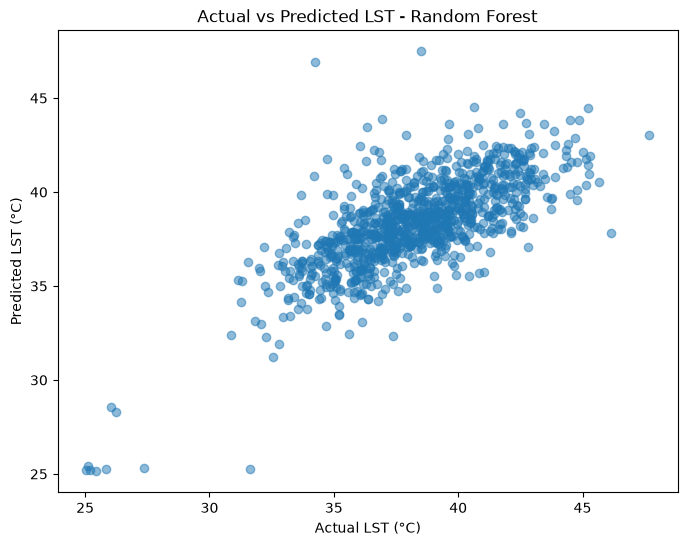

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_rf,
    alpha=0.5
)

plt.xlabel("Actual LST (°C)")
plt.ylabel("Predicted LST (°C)")
plt.title("Actual vs Predicted LST - Random Forest")

plt.show()

In [46]:
low_threshold = df["LST_C"].quantile(0.33)
high_threshold = df["LST_C"].quantile(0.66)

print("Heat Risk Thresholds")
print("--------------------")
print("Low Risk threshold    :", low_threshold)
print("High Risk threshold   :", high_threshold)

Heat Risk Thresholds
--------------------
Low Risk threshold    : 36.97546280000006
High Risk threshold   : 39.36807680000004


In [47]:
def classify_heat_risk(lst):
    if lst <= low_threshold:
        return "Low"
    elif lst <= high_threshold:
        return "Medium"
    else:
        return "High"

df["Heat_Risk"] = df["LST_C"].apply(classify_heat_risk)

print("Heat-risk classification completed!")
print(df[["LST_C", "Heat_Risk"]].head(10))

Heat-risk classification completed!
       LST_C Heat_Risk
0  42.085403      High
1  38.260638    Medium
2  35.844098       Low
3  41.958936      High
4  42.840785      High
5  43.845683      High
6  42.146927      High
7  39.043365    Medium
8  39.552650      High
9  38.578514    Medium


In [48]:
print(df["Heat_Risk"].value_counts())

Heat_Risk
High      1699
Low       1652
Medium    1649
Name: count, dtype: int64


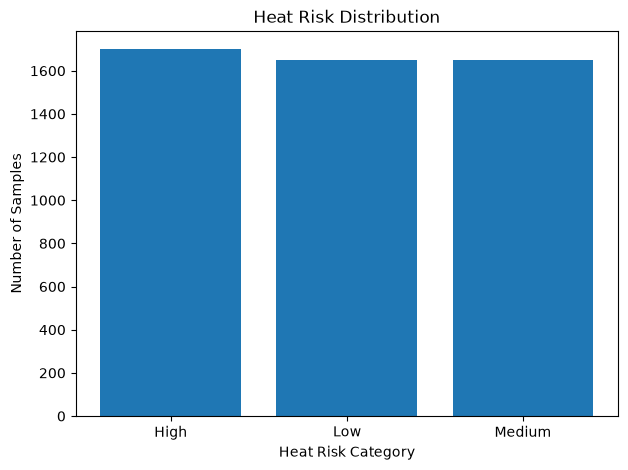

In [49]:
import matplotlib.pyplot as plt

risk_counts = df["Heat_Risk"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    risk_counts.index,
    risk_counts.values
)

plt.xlabel("Heat Risk Category")
plt.ylabel("Number of Samples")
plt.title("Heat Risk Distribution")

plt.show()

In [50]:
heat_risk_map = (
    lst
    .expression(
        "LST <= low ? 1 : (LST <= high ? 2 : 3)",
        {
            "LST": lst,
            "low": low_threshold,
            "high": high_threshold
        }
    )
    .rename("Heat_Risk")
)

Map = geemap.Map()

Map.centerObject(pune, 11)

Map.addLayer(
    heat_risk_map.clip(pune),
    {
        "min": 1,
        "max": 3,
        "palette": [
            "green",
            "yellow",
            "red"
        ]
    },
    "AI Urban Heat Risk Map"
)

Map.addLayer(
    pune,
    {},
    "Pune Study Area"
)

Map

Map(center=[18.55001529358942, 73.85000000000024], controls=(WidgetControl(options=['position', 'transparent_b…

In [51]:
df.to_csv("pune_urban_heat_dataset.csv", index=False)

print("Dataset saved successfully!")
print("File: pune_urban_heat_dataset.csv")
print("Rows:", len(df))
print("Columns:", df.columns.tolist())

Dataset saved successfully!
File: pune_urban_heat_dataset.csv
Rows: 5000
Columns: ['LST_C', 'NDBI', 'NDVI', 'NDWI', 'Heat_Risk']


In [52]:
import joblib

joblib.dump(rf_model, "urban_heat_random_forest.pkl")

print("Random Forest model saved successfully!")
print("File: urban_heat_random_forest.pkl")

Random Forest model saved successfully!
File: urban_heat_random_forest.pkl


In [53]:
rf_model_loaded = joblib.load("urban_heat_random_forest.pkl")

In [54]:
print("========== AI URBAN HEAT MAP ==========")

print("\n1. LST RANGE")
print("Minimum LST:", lst_stats.getInfo()["LST_C_min"], "°C")
print("Maximum LST:", lst_stats.getInfo()["LST_C_max"], "°C")

print("\n2. LINEAR REGRESSION")
print("MAE :", round(mae_linear, 4))
print("RMSE:", round(rmse_linear, 4))
print("R²  :", round(r2_linear, 4))

print("\n3. RANDOM FOREST")
print("MAE :", round(mae_rf, 4))
print("RMSE:", round(rmse_rf, 4))
print("R²  :", round(r2_rf, 4))

print("\n4. FEATURE IMPORTANCE")
print(feature_importance)

print("\n5. HEAT RISK DISTRIBUTION")
print(df["Heat_Risk"].value_counts())


========== AI URBAN HEAT MAP ==========

1. LST RANGE
Minimum LST: 24.38347712000001 °C
Maximum LST: 50.93123846000003 °C

2. LINEAR REGRESSION
MAE : 1.6279
RMSE: 2.1637
R²  : 0.4724

3. RANDOM FOREST
MAE : 1.5744
RMSE: 2.077
R²  : 0.5138

4. FEATURE IMPORTANCE
  Feature  Importance
1    NDBI    0.505954
2    NDWI    0.296682
0    NDVI    0.197364

5. HEAT RISK DISTRIBUTION
Heat_Risk
High      1699
Low       1652
Medium    1649
Name: count, dtype: int64
